# Lab 6 적용 — Keras MLP를 15만 건에 (Give Me Some Credit)

**Lab 5에서 넘어온 질문:** 신경망(MLP)은 지금까지의 최고 기준(RF 0.856)을 넘을 수 있을까? 그리고 15만 건을 어떻게 학습시킬까?

Lab 6의 순서를 그대로 따른다.
1. 첫 MLP: 은닉층 12-8, relu/sigmoid, adam, binary_crossentropy (Lab 6 구조 그대로)
2. 학습 데이터로 평가 (Lab 6 (c): 이 정확도를 믿을 수 있나?)
3. 검증 데이터 분리 (Manual Verification Dataset, 67:33) → **배치 크기 × 에폭 실험** (06a_batch_epoch_experiment.py)
4. k-fold 교차검증을 직접 반복 (StratifiedKFold)
5. KerasClassifier + cross_val_score
6. Grid Search (optimizer × 초기화)
7. 가중치 저장

공통 설정: 입력은 로그+표준화(학습 데이터로만 계산), 연체자 가중치(Lab 4), **배치 128**(실험 A에서 선택), **EarlyStopping**(검증 AUC가 10 에폭 동안 안 오르면 멈추고 가장 좋았던 가중치로 되돌림, 최대 150 에폭).

In [1]:
import os, time, glob
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import numpy
from pandas import read_csv, DataFrame
from matplotlib import pyplot, font_manager
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split, GridSearchCV
from sklearn.metrics import roc_auc_score, accuracy_score
import tensorflow as tf
tf.get_logger().setLevel('ERROR')        # 반복 학습 시 나오는 retracing 경고 숨김
import keras
from keras import layers
from keras_wrapper import KerasClassifier

for p in glob.glob(os.path.expandvars(r'%LOCALAPPDATA%\Microsoft\Windows\Fonts\Pretendard-*.ttf')):
    font_manager.fontManager.addfont(p)
pyplot.rcParams['font.family'] = 'Pretendard'
pyplot.rcParams['axes.unicode_minus'] = False
BLUE, RED, GRAY, VIOLET, INK = '#3182F6', '#F04452', '#B0B8C1', '#7C5CFF', '#191F28'

SMOKE = os.environ.get('SMOKE') == '1'          # 코드 점검용 작은 실행
BATCH, MAX_EPOCHS, PATIENCE = 128, (3 if SMOKE else 150), (1 if SMOKE else 10)
seed = 7

names = ['target', 'revol', 'age', 'late30', 'debt', 'income', 'depend', 'defaulted', 'loans']
features = names[1:]
dataframe = read_csv('../data/givemesomecredit.csv', names=names, header=0)
X = dataframe.values[:, 1:9].astype(float)
Y = dataframe.values[:, 0].astype(int)
if SMOKE:
    X, _, Y, _ = train_test_split(X, Y, train_size=6000, random_state=seed, stratify=Y)
LOGC = [features.index(c) for c in ['revol', 'late30', 'debt', 'income']]

def log4(A):
    A = A.copy(); A[:, LOGC] = numpy.log1p(A[:, LOGC]); return A

def weights_for(y):
    return {0: 1.0, 1: float((y == 0).sum() / (y == 1).sum())}

def create_model(optimizer='adam', init='glorot_uniform'):
    # Lab 6 구조 그대로: 8 → 12(relu) → 8(relu) → 1(sigmoid)
    model = keras.Sequential([
        layers.Input((8,)),
        layers.Dense(12, kernel_initializer=init, activation='relu'),
        layers.Dense(8, kernel_initializer=init, activation='relu'),
        layers.Dense(1, kernel_initializer=init, activation='sigmoid'),
    ])
    model.compile(loss='binary_crossentropy', optimizer=optimizer,
                  metrics=['accuracy', keras.metrics.AUC(name='auc')])
    return model

def early_stop():
    return keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=PATIENCE, restore_best_weights=True)

print(X.shape, '연체 비율', Y.mean().round(4), '· SMOKE' if SMOKE else '')

(150000, 8) 연체 비율 0.0668 


## 1~2. 첫 MLP, 그리고 학습 데이터로 평가 (Lab 6 (b)(c))

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.33, random_state=seed, stratify=Y)
scaler = StandardScaler().fit(log4(X_train))
Xtr = scaler.transform(log4(X_train)).astype('float32'); Xte = scaler.transform(log4(X_test)).astype('float32')
keras.utils.set_random_seed(seed)
model = create_model()
t0 = time.time()
hist = model.fit(Xtr, y_train, epochs=MAX_EPOCHS, batch_size=BATCH, verbose=0, class_weight=weights_for(y_train),
                 validation_split=0.1, callbacks=[early_stop()])
fit_sec = time.time() - t0
stop_epoch = len(hist.history['loss']); best_epoch = int(numpy.argmax(hist.history['val_auc'])) + 1
p_tr = model.predict(Xtr, batch_size=8192, verbose=0).ravel(); p_te = model.predict(Xte, batch_size=8192, verbose=0).ravel()
print(f'학습 {fit_sec:.1f}초 · {stop_epoch} 에폭에서 멈춤 (가장 좋았던 에폭 {best_epoch})')
print(f'학습 데이터로 평가:  정확도 {accuracy_score(y_train, p_tr >= 0.5):.4f} · AUC {roc_auc_score(y_train, p_tr):.4f}')
print(f'시험 데이터로 평가:  정확도 {accuracy_score(y_test, p_te >= 0.5):.4f} · AUC {roc_auc_score(y_test, p_te):.4f}')

학습 37.4초 · 32 에폭에서 멈춤 (가장 좋았던 에폭 22)
학습 데이터로 평가:  정확도 0.7627 · AUC 0.8523
시험 데이터로 평가:  정확도 0.7610 · AUC 0.8513


**(c) 이 정확도를 믿을 수 있나?** Lab 6 예제는 학습에 쓴 데이터로 평가해 '학습 정확도'만 보여 준다. 처음 보는 데이터에서의 성능은 알 수 없다.
그래서 시험 데이터(33%)를 따로 떼어 비교했다. 또 연체자 가중치를 줬기 때문에 정확도는 '전부 정상' 기준선(93.3%)보다 낮게 나온다.
연체자를 더 많이 연체로 판정하기 때문이며, 그래서 평가는 AUC로 한다.

## 3. 검증 데이터 분리 → 배치 크기 × 에폭 실험 (06a_batch_epoch_experiment.py 결과)

In [3]:
r = read_csv('06a_batch_epoch_results.csv')
E = [1, 5, 10, 25, 50, 100, 150]
s = r[r.epoch.isin(E)]
print('검증 AUC'); print(s.pivot(index='batch', columns='epoch', values='val_auc').round(4).to_string())
print(); print('그 에폭까지 순수 학습 시간(초)'); print(s.pivot(index='batch', columns='epoch', values='train_sec').round(1).to_string())

검증 AUC
epoch     1       5       10      25      50      100     150
batch                                                        
10     0.8477  0.8520  0.8525  0.8535  0.8541  0.8540  0.8539
32     0.8463  0.8514  0.8522  0.8524  0.8531  0.8537  0.8546
128    0.8412  0.8492  0.8512  0.8523  0.8525  0.8535  0.8542
512    0.8199  0.8462  0.8492  0.8515  0.8524  0.8524  0.8524
2048   0.5661  0.8339  0.8428  0.8478  0.8504  0.8514  0.8513

그 에폭까지 순수 학습 시간(초)
epoch   1     5     10     25     50     100     150
batch                                               
10     11.2  48.6  90.3  215.4  446.6  964.3  1569.9
32      4.2  19.8  37.8   99.0  227.0  431.1   617.6
128     1.3   5.0   9.2   20.6   39.9   80.9   123.6
512     0.8   1.8   3.0    6.9   14.1   26.3    37.7
2048    0.7   1.1   1.6    3.3    5.8   10.9    15.8


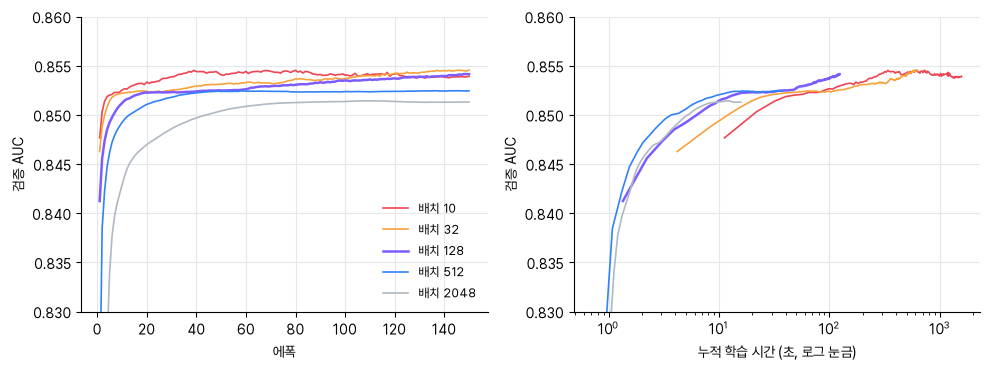

In [4]:
fig, axes = pyplot.subplots(1, 2, figsize=(10, 3.8))
cols = {10: RED, 32: '#F7A23B', 128: VIOLET, 512: BLUE, 2048: GRAY}
for b, g in r.groupby('batch'):
    axes[0].plot(g.epoch, g.val_auc, color=cols[b], lw=1.8 if b == 128 else 1.2, label=f'배치 {b}')
    axes[1].plot(g.train_sec, g.val_auc, color=cols[b], lw=1.8 if b == 128 else 1.2, label=f'배치 {b}')
axes[0].set_xlabel('에폭'); axes[1].set_xlabel('누적 학습 시간 (초, 로그 눈금)'); axes[1].set_xscale('log')
for ax in axes:
    ax.set_ylim(0.83, 0.86); ax.set_ylabel('검증 AUC'); ax.grid(color='#E5E8EB'); ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(frameon=False, fontsize=9, loc='lower right')
pyplot.tight_layout(); pyplot.savefig('../figures/lab6_batch_epoch.png', dpi=200); pyplot.show()

배치 크기와 상관없이 AUC는 0.851~0.855에 모였고, 시간은 배치 10(150 에폭 26분)과 배치 2048(16초) 사이에 100배 차이가 났다.
Lab 6 설정(배치 10, 150 에폭)이면 모델 하나에 26분, 10-fold면 약 6시간이 걸린다(fold마다 13.5만 건). 그래서 0.854로 최상위권이면서 13배 빠른 **배치 128**을 고르고,
에폭은 고정하지 않고 **EarlyStopping**으로 정한다(실험에서 배치 512는 50 에폭 뒤로 AUC가 더 오르지 않았다).

## 4. k-fold 교차검증을 직접 반복 (Lab 6: `for train, test in kfold.split(X, Y)`)

In [5]:
kfold = StratifiedKFold(n_splits=(3 if SMOKE else 10), shuffle=True, random_state=seed)
cvscores, stops, secs = [], [], []
for k, (train, test) in enumerate(kfold.split(X, Y), 1):
    sc = StandardScaler().fit(log4(X[train]))                       # fold의 학습 데이터로만 (누수 방지)
    a, b = sc.transform(log4(X[train])).astype('float32'), sc.transform(log4(X[test])).astype('float32')
    keras.utils.set_random_seed(seed)
    model = create_model()
    t0 = time.time()
    h = model.fit(a, Y[train], epochs=MAX_EPOCHS, batch_size=BATCH, verbose=0, class_weight=weights_for(Y[train]),
                  validation_split=0.1, callbacks=[early_stop()])
    secs.append(time.time() - t0); stops.append(len(h.history['loss']))
    cvscores.append(roc_auc_score(Y[test], model.predict(b, batch_size=8192, verbose=0).ravel()))
    print(f'fold {k:>2}: AUC {cvscores[-1]:.4f} · {stops[-1]} 에폭에서 멈춤 · {secs[-1]:.0f}초')
print(f'MLP 층화 10-fold AUC: {numpy.mean(cvscores):.4f} (+/- {numpy.std(cvscores):.4f}) · fold당 평균 {numpy.mean(secs):.0f}초 · 평균 {numpy.mean(stops):.0f} 에폭')

fold  1: AUC 0.8574 · 22 에폭에서 멈춤 · 37초


fold  2: AUC 0.8456 · 29 에폭에서 멈춤 · 43초


fold  3: AUC 0.8677 · 71 에폭에서 멈춤 · 105초


fold  4: AUC 0.8431 · 145 에폭에서 멈춤 · 228초


fold  5: AUC 0.8549 · 23 에폭에서 멈춤 · 37초


fold  6: AUC 0.8464 · 28 에폭에서 멈춤 · 47초


fold  7: AUC 0.8526 · 33 에폭에서 멈춤 · 53초


fold  8: AUC 0.8411 · 19 에폭에서 멈춤 · 30초


fold  9: AUC 0.8470 · 35 에폭에서 멈춤 · 56초


fold 10: AUC 0.8489 · 24 에폭에서 멈춤 · 39초
MLP 층화 10-fold AUC: 0.8505 (+/- 0.0075) · fold당 평균 67초 · 평균 43 에폭


**(g) 왜 for 반복문이 필요한가?** fold마다 모델을 새로 만들어야 한다. 이전 fold에서 학습한 가중치가 남아 있으면 그 fold의 시험 데이터를 이미 본 셈이 되기 때문이다. 표준화도 fold마다 새로 맞췄다.

## 5. KerasClassifier + cross_val_score (Lab 6 3절)

In [6]:
mlp = Pipeline([('log', FunctionTransformer(log4)), ('standardize', StandardScaler()),
                ('mlp', KerasClassifier(build_fn=create_model, epochs=MAX_EPOCHS, batch_size=BATCH, verbose=0,
                                        validation_split=0.1, callbacks=early_stop,
                                        class_weight=weights_for(Y)))])
keras.utils.set_random_seed(seed)
t0 = time.time()
results = cross_val_score(mlp, X, Y, cv=kfold, scoring='roc_auc')
wrap_sec = time.time() - t0
print(f'KerasClassifier 층화 10-fold AUC: {results.mean():.4f} (+/- {results.std():.4f}) · {wrap_sec / 60:.1f}분')

KerasClassifier 층화 10-fold AUC: 0.8513 (+/- 0.0066) · 16.0분


**(h)(i)** 직접 반복한 4번과 거의 같은 결과가 코드 몇 줄로 나온다. 래퍼 덕분에 MLP도 sklearn의 Pipeline·cross_val_score·GridSearchCV 안에 다른 모델처럼 넣을 수 있다.
(최신 Keras에는 원래 래퍼가 없어 같은 역할을 하는 `keras_wrapper.py`를 만들어 썼다.)

## 6. Grid Search (Lab 6: optimizer × init × epochs × batch, 3-fold)

In [7]:
# Lab 6 격자를 15만 건에 그대로 쓰면? (실험 A의 배치 10 에폭당 시간으로 계산, 학습 데이터 2/3 = 10만 건)
sec10 = r[r.batch == 10].train_sec.max() / 150
hours10 = 2 * 3 * sum([50, 100, 150]) * 3 * sec10 / 3600   # optimizer 2 × init 3 × 에폭(50+100+150) × fold 3, 배치 10만
print(f'배치 10 에폭당 {sec10:.1f}초 → Lab 6 격자 중 배치 10 조합(18가지 × 3-fold)만 약 {hours10:.0f}시간')
print('배치 5(약 2배 느림)·20까지 더하면 이틀 이상 → 15만 건에는 그대로 쓸 수 없다')

배치 10 에폭당 10.5초 → Lab 6 격자 중 배치 10 조합(18가지 × 3-fold)만 약 16시간
배치 5(약 2배 느림)·20까지 더하면 이틀 이상 → 15만 건에는 그대로 쓸 수 없다


In [8]:
# 그래서 배치(128)와 에폭(EarlyStopping)은 실험 A로 정하고, optimizer × 초기화 6가지만 격자로 찾는다.
param_grid = dict(mlp__optimizer=['rmsprop', 'adam'],
                  mlp__init=['glorot_uniform', 'random_normal', 'random_uniform'])   # Lab의 normal·uniform = Keras 3 이름
keras.utils.set_random_seed(seed)
t0 = time.time()
grid = GridSearchCV(estimator=mlp, param_grid=param_grid, scoring='roc_auc',
                    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=seed))
grid_result = grid.fit(X, Y)
grid_sec = time.time() - t0
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
for mean, stdev, param in zip(grid_result.cv_results_['mean_test_score'], grid_result.cv_results_['std_test_score'], grid_result.cv_results_['params']):
    print("%f (%f) with: %r" % (mean, stdev, param))
print(f'{grid_sec / 60:.1f}분')

Best: 0.850128 using {'mlp__init': 'glorot_uniform', 'mlp__optimizer': 'adam'}
0.849186 (0.003607) with: {'mlp__init': 'glorot_uniform', 'mlp__optimizer': 'rmsprop'}
0.850128 (0.004379) with: {'mlp__init': 'glorot_uniform', 'mlp__optimizer': 'adam'}
0.849155 (0.004106) with: {'mlp__init': 'random_normal', 'mlp__optimizer': 'rmsprop'}
0.849635 (0.001622) with: {'mlp__init': 'random_normal', 'mlp__optimizer': 'adam'}
0.849029 (0.003630) with: {'mlp__init': 'random_uniform', 'mlp__optimizer': 'rmsprop'}
0.849140 (0.003889) with: {'mlp__init': 'random_uniform', 'mlp__optimizer': 'adam'}
20.7분


## 7. 가중치 저장 (Lab 6: `model.get_weights()` → weights.out)

In [9]:
# 최종 MLP: 15만 건 전체로 학습. 에폭은 10-fold에서 멈춘 에폭의 중앙값으로 고정
best = grid_result.best_params_
final_epochs = int(numpy.median(stops))
sc_full = StandardScaler().fit(log4(X))
Xall = sc_full.transform(log4(X)).astype('float32')
keras.utils.set_random_seed(seed)
final = create_model(optimizer=best['mlp__optimizer'], init=best['mlp__init'])
t0 = time.time()
final.fit(Xall, Y, epochs=final_epochs, batch_size=BATCH, verbose=0, class_weight=weights_for(Y))
print(f'최종 MLP: 15만 건 · {final_epochs} 에폭 · {time.time() - t0:.0f}초')
try:
    os.remove('weights.out'); print('old file deleted')
except OSError:
    print('no file to delete')
with open('weights.out', 'ab') as f:
    for item in final.get_weights():
        numpy.savetxt(f, numpy.atleast_2d(item), delimiter=',')
final.save('lab6_mlp.keras')
n_params = sum(w.size for w in final.get_weights())
print(f'가중치 {n_params}개 · weights.out {os.path.getsize("weights.out") / 1e3:.1f} KB · lab6_mlp.keras {os.path.getsize("lab6_mlp.keras") / 1e3:.1f} KB')

최종 MLP: 15만 건 · 28 에폭 · 50초
old file deleted
가중치 221개 · weights.out 5.6 KB · lab6_mlp.keras 28.6 KB


## 모델 비교 (모두 층화 10-fold AUC)

              모델    AUC   표준편차
  LR 가중치 (Lab 4) 0.8436 0.0073
AdaBoost (Lab 5) 0.8471 0.0069
   RF 튜닝 (Lab 5) 0.8556 0.0070
MLP 12-8 (Lab 6) 0.8505 0.0075


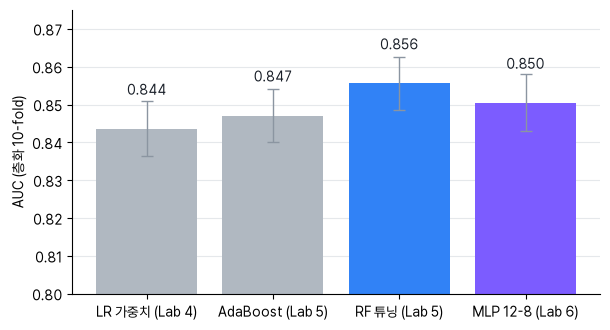

In [10]:
mlp_auc, mlp_std = numpy.mean(cvscores), numpy.std(cvscores)
table = DataFrame([('LR 가중치 (Lab 4)', 0.8436, 0.0073), ('AdaBoost (Lab 5)', 0.8471, 0.0069),
                   ('RF 튜닝 (Lab 5)', 0.8556, 0.0070), ('MLP 12-8 (Lab 6)', mlp_auc, mlp_std)],
                  columns=['모델', 'AUC', '표준편차'])
print(table.round(4).to_string(index=False))
fig, ax = pyplot.subplots(figsize=(6.2, 3.4))
ax.bar(table['모델'], table['AUC'], yerr=table['표준편차'], color=[GRAY, GRAY, BLUE, VIOLET], capsize=4,
       error_kw={'ecolor': '#8B95A1', 'lw': 1})
for i, v in enumerate(table['AUC']):
    ax.text(i, v + 0.009, f'{v:.3f}', ha='center', fontsize=10, color=INK)
ax.set_ylim(0.80, 0.875); ax.set_ylabel('AUC (층화 10-fold)')
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', color='#E5E8EB'); ax.set_axisbelow(True)
pyplot.tight_layout(); pyplot.savefig('../figures/lab6_compare.png', dpi=200); pyplot.show()

## 정리: 발견 → 결론
- 발견 1: **배치 크기는 성능이 아니라 시간을 정했다.** 150 에폭에서 배치 10~2048 모두 AUC 0.851~0.855, 시간은 26분 vs 16초. Lab 6 설정(배치 10, 150 에폭)이면 10-fold에 약 6시간(fold마다 13.5만 건), Grid Search는 이틀 이상 → 배치 128 + EarlyStopping 선택.
- 발견 2: **MLP 층화 10-fold AUC 0.850 (± 0.008)**, fold당 67초, 평균 43 에폭에서 멈춤. KerasClassifier로도 0.851로 같았다.
- 발견 3: **Grid Search 6가지(optimizer × 초기화)는 0.849~0.850**으로 차이가 흔들림 안. Lab 기본값(adam, glorot)이 최고.
- 발견 4: 학습 데이터 AUC 0.852 vs 시험 0.851 → EarlyStopping으로 과적합 없이 멈췄다. 정확도 76%는 연체자 가중치 때문(정확도는 '전부 정상' 93.3%가 이기는 지표).

**목표(연체 예측)에 대한 결론:** MLP(0.850)는 튜닝한 RF(0.856)를 넘지 못했고 15만 건 학습도 16배 느렸다(50초 vs 3초). 변수 8개의 표 데이터에서는 트리 앙상블이 효율적 → **최종 모델은 데이터 정리 + RF(잎 176명)**.